# Video Game Sales Prediction on Steam Data
## Notebook 11 — The Final Model

**Purpose.** Notebooks 5–10 changed one thing at a time, and the reference model changed four times along the
way. This notebook closes the modelling:
1. **Tuning.** Every model so far used default settings. The analogy model of Notebook 10 is tuned, with the
   settings chosen on earlier release years than those used to evaluate them.
2. **Validation.** The final model is put through every evaluation used in this study.
3. **Interpretation.** Which variable groups the final model relies on, and where it still fails.
4. **Final comparison.** Every model from the first parent paper's method to the final one, on the same
   evaluations, in one table.

**Evaluations used throughout.**
- **Random folds:** 5-fold cross-validation on the training set (61,381 games), as in Notebooks 3–10.
- **One year ahead:** each of 2022, 2023 and 2024 predicted by a model fitted on all earlier training-set games
  (Notebook 8). This is the closest to a real forecast.
- **Test set:** 15,346 games held out since Notebook 3, used once per model.

**Target.** log1p(estimated owners), the midpoint of the SteamSpy owner range (Notebook 5). R² on this scale is
the headline measure; R² and mean absolute error in owners are also reported in the final comparison.

In [1]:
import itertools
import json
import os
import textwrap
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold, KFold, train_test_split
from sklearn.tree import DecisionTreeRegressor

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
BLUE, GREEN, ORANGE, RED, GREY, PURPLE = "#4C72B0", "#55A868", "#DD8452", "#C44E52", "#8C8C8C", "#8172B3"
RANDOM_STATE = 42
SEEDS = [42, 1, 2, 3, 4]

FIG_DIR = os.path.join("..", "outputs", "figures")
TAB_DIR = os.path.join("..", "outputs", "tables")
DATA_DIR = os.path.join("..", "data", "processed")

data = pd.read_csv(os.path.join(DATA_DIR, "steam_model_table.csv.gz"), parse_dates=["release_dt"])
with open(os.path.join(DATA_DIR, "features.json")) as f:
    spec = json.load(f)
with open(os.path.join(DATA_DIR, "engineered_features.json")) as f:
    groups = json.load(f)
for name in ["engineered_features.csv.gz", "predecessor_features.csv.gz"]:      # written by Notebooks 7 and 10
    data = data.merge(pd.read_csv(os.path.join(DATA_DIR, name)), on="appid", how="left", validate="one_to_one")

BASE = spec["numeric"] + spec["genres"] + spec["categories"]                     # Notebook 1 (42)
STORE_PAGE = BASE + groups["A. Studio experience"] + groups["C. Store-page lead time"]   # Notebook 7 (49)
PREDECESSOR = ["series_prev_log_owners", "series_gap_years", "dev_prev_log_owners", "dev_gap_years",
               "pub_prev_log_owners", "pub_gap_years"]
STUDIO_AVERAGES = groups["Past sales (sensitivity only)"]
ANALOGY = STORE_PAGE + PREDECESSOR + STUDIO_AVERAGES                             # Notebook 10 (59)
data["owners"] = (data["owners_millions"] * 1e6).round()
data["log_owners"] = np.log1p(data["owners"])

train, test = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE)
train, test = train.reset_index(drop=True), test.reset_index(drop=True)
folds = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(train))
print(f"Training set {len(train):,} games, test set {len(test):,}; analogy model: {len(ANALOGY)} variables")

Training set 61,381 games, test set 15,346; analogy model: 59 variables


---
# 16. The Final Model

## 16.1 Tuning

**Settings searched.** 36 combinations of four Gradient Boosting settings: learning rate (0.03, 0.1), maximum
leaves per tree (15, 31, 63), minimum games per leaf (20, 50, 200) and L2 regularisation (0, 1). The number of
trees is set by early stopping, up to 1,000.

**How the settings are chosen without overstating the result.** Each setting is scored by predicting 2019, 2020
and 2021 releases, each from all earlier games. The best setting is then evaluated on 2022–2024, which played no
part in the choice, and with random folds. This keeps the choice and the evaluation separate in time, the
equivalent of nested cross-validation for a forecast.

**Adoption rule.** The tuned settings replace the defaults only if they raise one-year-ahead R² (log) on
2022–2024 by at least 0.01 (mean of five seeds) and do not lower the random-fold score.

In [2]:
TUNING_YEARS = (2019, 2020, 2021)      # used to choose settings
AHEAD_YEARS = (2022, 2023, 2024)       # used only to evaluate them


def gb(params=None, seed=RANDOM_STATE):
    return HistGradientBoostingRegressor(random_state=seed, **(params or {}))


def one_year_ahead_r2(model, features, years, seeds=(RANDOM_STATE,)):
    """Mean R² (log) over the given years, each predicted from all earlier training-set games."""
    values = []
    for year in years:
        earlier, target = train[train["release_year"] < year], train[train["release_year"] == year]
        for seed in seeds:
            m = clone(model).set_params(random_state=seed)
            values.append(r2_score(target["log_owners"], m.fit(earlier[features], earlier["log_owners"]).predict(target[features])))
    return float(np.mean(values))


def random_fold_r2(model, features, fold_list=folds):
    oof = np.zeros(len(train))
    for tr, va in fold_list:
        oof[va] = clone(model).fit(train.iloc[tr][features], train["log_owners"].to_numpy()[tr]).predict(train.iloc[va][features])
    return r2_score(train["log_owners"], oof), oof

In [3]:
GRID = {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [15, 31, 63],
        "min_samples_leaf": [20, 50, 200], "l2_regularization": [0.0, 1.0]}
start = time.time()
rows = []
for values in itertools.product(*GRID.values()):
    params = dict(zip(GRID, values), max_iter=1000)    # early stopping (on by default) decides the number of trees
    rows.append({**params, "Tuning years 2019–2021: R² (log)": one_year_ahead_r2(gb(params), ANALOGY, TUNING_YEARS)})
grid = pd.DataFrame(rows).sort_values("Tuning years 2019–2021: R² (log)", ascending=False).reset_index(drop=True)
default_tuning = one_year_ahead_r2(gb(), ANALOGY, TUNING_YEARS)
best = grid.iloc[0][list(GRID) + ["max_iter"]].to_dict()
best = {k: (int(v) if k in ("max_leaf_nodes", "min_samples_leaf", "max_iter") else float(v)) for k, v in best.items()}
grid.to_csv(os.path.join(TAB_DIR, "table55_tuning_grid.csv"), index=False)
print(f"{len(grid)} settings in {time.time() - start:.0f} s | default settings: {default_tuning:.3f} | best: "
      f"{grid.iloc[0]['Tuning years 2019–2021: R² (log)']:.3f} with {best}")
grid.head(10).style.format({"learning_rate": "{:.2f}", "l2_regularization": "{:.1f}",
                            "Tuning years 2019–2021: R² (log)": "{:.3f}"}).set_caption(
    "Table 55. The ten best of 36 settings, chosen on 2019–2021 releases (each predicted from earlier years)")

36 settings in 173 s | default settings: 0.373 | best: 0.377 with {'learning_rate': 0.03, 'max_leaf_nodes': 31, 'min_samples_leaf': 50, 'l2_regularization': 1.0, 'max_iter': 1000}


,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,max_iter,Tuning years 2019–2021: R² (log)
0,0.03,31,50,1.0,1000,0.377
1,0.03,63,50,1.0,1000,0.377
2,0.03,31,50,0.0,1000,0.377
3,0.03,63,50,0.0,1000,0.377
4,0.03,63,20,1.0,1000,0.377
5,0.03,63,20,0.0,1000,0.377
6,0.03,31,20,0.0,1000,0.377
7,0.03,31,20,1.0,1000,0.376
8,0.03,15,50,0.0,1000,0.375
9,0.03,15,20,0.0,1000,0.374


In [4]:
rows = []
for name, params in [("Default settings (Notebook 10)", None), ("Tuned settings", best)]:
    model = gb(params)
    rows.append({"Settings": name, "Tuning years 2019–2021": one_year_ahead_r2(model, ANALOGY, TUNING_YEARS),
                 "Evaluation years 2022–2024 (5 seeds)": one_year_ahead_r2(model, ANALOGY, AHEAD_YEARS, SEEDS),
                 "Random folds": random_fold_r2(model, ANALOGY)[0]})
table56 = pd.DataFrame(rows).set_index("Settings")
gain_ahead = table56["Evaluation years 2022–2024 (5 seeds)"].diff().iloc[-1]
gain_random = table56["Random folds"].diff().iloc[-1]
ADOPT_TUNED = gain_ahead >= 0.01 and gain_random >= 0
FINAL_PARAMS = best if ADOPT_TUNED else None
table56.to_csv(os.path.join(TAB_DIR, "table56_tuning_result.csv"))
print(f"Gain one year ahead (2022–2024): {gain_ahead:+.3f} | gain with random folds: {gain_random:+.3f} | "
      f"tuned settings {'adopted' if ADOPT_TUNED else 'not adopted'}")
table56.style.format("{:.3f}").set_caption("Table 56. Default against tuned settings, analogy model, R² (log)")

Gain one year ahead (2022–2024): +0.004 | gain with random folds: +0.002 | tuned settings not adopted


,Tuning years 2019–2021,Evaluation years 2022–2024 (5 seeds),Random folds
Settings,,,
Default settings (Notebook 10),0.373,0.311,0.502
Tuned settings,0.377,0.315,0.504


**Interpretation.**
- **Tuning helps very little.** On the tuning years the best setting (learning rate 0.03, 31 leaves, at least
  50 games per leaf, L2 regularisation 1) scores 0.377 against 0.373 for the defaults, and the ten best settings
  lie within 0.004 of each other.
- **The small gain carries over but stays below the rule.** On 2022–2024 the tuned model scores 0.315 against
  0.311 (+0.004), and 0.504 against 0.502 with random folds (+0.002). The tuned settings are **not adopted**.
- **The default settings were already close to the best available.** The limit of the model is the information
  in its variables, not how it is fitted. The final model is the analogy model of Notebook 10 with default
  settings.

## 16.2 Validation of the final model

Every evaluation of the study is repeated for the final model: random folds, folds grouped by normalised title
(so re-releases of one title cannot sit in both training and validation folds), one year ahead overall and by
group, and the held-out test set.

In [5]:
def title_key(names):
    k = names.fillna("").str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
    return k.where(k != "", "row" + pd.Series(range(len(k)), index=k.index).astype(str))


final_model = gb(FINAL_PARAMS)
grouped_folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(train, groups=title_key(train["name"])))
final_random, final_oof = random_fold_r2(final_model, ANALOGY)
final_grouped, _ = random_fold_r2(final_model, ANALOGY, grouped_folds)

# One year ahead, keeping every prediction for the error analysis
ahead = []
for year in AHEAD_YEARS:
    earlier, target = train[train["release_year"] < year], train[train["release_year"] == year]
    for seed in SEEDS:
        pred = clone(final_model).set_params(random_state=seed).fit(earlier[ANALOGY], earlier["log_owners"]).predict(target[ANALOGY])
        ahead.append(target[["appid", "name", "release_year", "owners", "log_owners", "analogy_type", "price"]]
                     .assign(seed=seed, pred=pred))
ahead = pd.concat(ahead, ignore_index=True)


def ahead_r2(mask=None):
    p = ahead if mask is None else ahead[mask]
    return p.groupby(["release_year", "seed"]).apply(lambda g: r2_score(g["log_owners"], g["pred"])).mean()


rows = [("Random folds", final_random), ("Random folds grouped by title", final_grouped),
        ("One year ahead, all games", ahead_r2())]
for kind in ["Series predecessor", "Developer's previous game", "Publisher's previous game", "No predecessor"]:
    rows.append((f"One year ahead, {kind.lower()}", ahead_r2(ahead["analogy_type"] == kind)))
rows += [("One year ahead, paid games", ahead_r2(ahead["price"] > 0)),
         ("One year ahead, free-to-play games", ahead_r2(ahead["price"] == 0))]
fitted_final = clone(final_model).fit(train[ANALOGY], train["log_owners"])
test_pred = fitted_final.predict(test[ANALOGY])                                    # the test set is used once
rows.append(("Test set", r2_score(test["log_owners"], test_pred)))
table57 = pd.DataFrame(rows, columns=["Evaluation", "R² (log)"]).set_index("Evaluation")
table57.to_csv(os.path.join(TAB_DIR, "table57_final_validation.csv"))
table57.style.format("{:.3f}").set_caption("Table 57. The final model under every evaluation used in this study")

C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16916\1026454439.py:24: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby(["release_year", "seed"]).apply(lambda g: r2_score(g["log_owners"], g["pred"])).mean()
C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16916\1026454439.py:24: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby(["release_year", "seed"]).apply(lambda g: r2_score(g["log_owners"

,R² (log)
Evaluation,
Random folds,0.502
Random folds grouped by title,0.498
"One year ahead, all games",0.311
"One year ahead, series predecessor",0.588
"One year ahead, developer's previous game",0.395
"One year ahead, publisher's previous game",0.355
"One year ahead, no predecessor",0.089
"One year ahead, paid games",0.342
"One year ahead, free-to-play games",-0.035


**Interpretation.**
- **The final model is stable across evaluations.** R² (log) is 0.502 with random folds, 0.498 with folds
  grouped by title and 0.486 on the test set.
- **One year ahead it reaches 0.311**, and the split by predecessor of Notebook 10 holds: 0.588 for games with a
  series predecessor, 0.396 with a developer's previous game, 0.355 with only a publisher's, and 0.089 for games
  with none.
- **Free-to-play games cannot be forecast one year ahead.** Their R² is −0.035, worse than predicting the
  average, against 0.342 for paid games. Free-to-play games are 11% of the data and include the largest misses
  (Section 16.3). This is a new limitation; with random folds the free-to-play segment looked only somewhat
  harder (Notebook 9).

## 16.3 What the final model relies on, and where it fails

**Permutation importance** by variable group, on the validation folds, as in Notebooks 5 and 7: the drop in R²
(log) when all variables of a group are shuffled together.

**Remaining errors**, from the one-year-ahead predictions for 2022–2024: errors by actual owner range, and the
largest under-predictions. The error is predicted minus actual log owners, so a negative mean means the model
predicts too few owners.

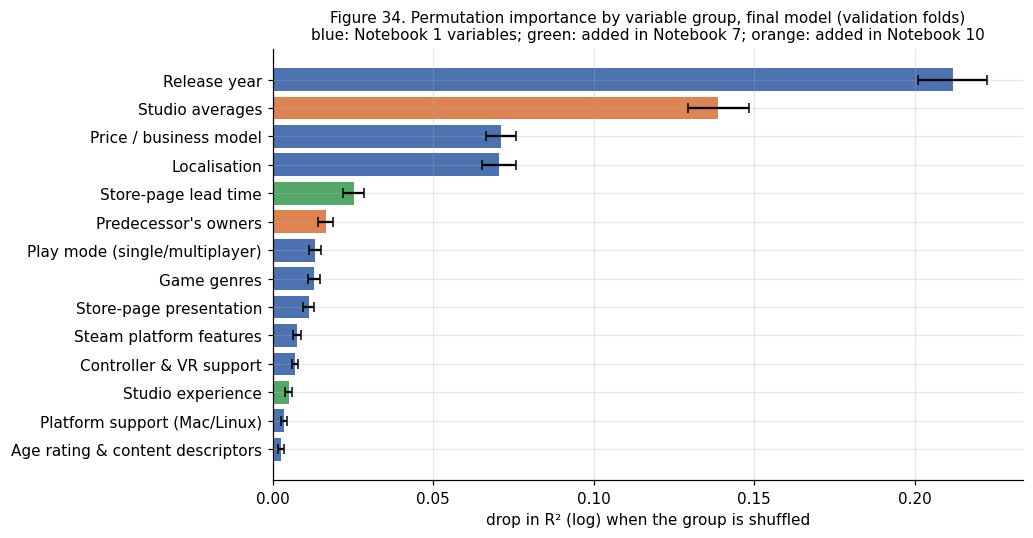

,Variables,Drop in R² (log) when shuffled,SD
Variable group,,,
Release year,1,0.212,0.011
Studio averages,4,0.139,0.010
Price / business model,2,0.071,0.005
Localisation,2,0.071,0.005
Store-page lead time,2,0.025,0.003
Predecessor's owners,6,0.017,0.002
Play mode (single/multiplayer),9,0.013,0.002
Game genres,11,0.013,0.002
Store-page presentation,2,0.011,0.002


In [6]:
FEATURE_GROUPS = {
    "Price / business model": ["price", "genre_Free_To_Play"],
    "Release year": ["release_year"],
    "Localisation": ["n_languages", "n_audio_languages"],
    "Platform support (Mac/Linux)": ["mac", "linux"],
    "Store-page presentation": ["n_screenshots", "description_length"],
    "Age rating & content descriptors": ["required_age", "genre_Violent", "genre_Gore", "genre_Nudity"],
    "Game genres": ["genre_Indie", "genre_Casual", "genre_Action", "genre_Adventure", "genre_Simulation",
                    "genre_Strategy", "genre_RPG", "genre_Sports", "genre_Racing", "genre_Massively_Multiplayer",
                    "genre_Education"],
    "Play mode (single/multiplayer)": ["cat_Single_player", "cat_Multi_player", "cat_PvP", "cat_Co_op",
                                       "cat_Online_PvP", "cat_Online_Co_op", "cat_Shared_Split_Screen",
                                       "cat_Shared_Split_Screen_PvP", "cat_Shared_Split_Screen_Co_op"],
    "Controller & VR support": ["cat_Full_controller_support", "cat_Partial_Controller_Support",
                                "cat_Tracked_Controller_Support", "cat_VR_Only"],
    "Steam platform features": ["cat_Steam_Cloud", "cat_Steam_Leaderboards", "cat_Stats",
                                "cat_Includes_level_editor", "cat_Captions_available"],
    "Studio experience": groups["A. Studio experience"],
    "Store-page lead time": groups["C. Store-page lead time"],
    "Predecessor's owners": PREDECESSOR,
    "Studio averages": STUDIO_AVERAGES,
}
assert sorted(c for cols in FEATURE_GROUPS.values() for c in cols) == sorted(ANALOGY)

drops = {g: [] for g in FEATURE_GROUPS}
y = train["log_owners"].to_numpy()
for i, (tr, va) in enumerate(folds):
    m = clone(final_model).fit(train.iloc[tr][ANALOGY], y[tr])
    X_va = train.iloc[va][ANALOGY]
    base = r2_score(y[va], m.predict(X_va))
    rng = np.random.default_rng(RANDOM_STATE + i)
    for g, cols in FEATURE_GROUPS.items():
        for _ in range(5):
            shuffled = X_va.copy()
            shuffled[cols] = shuffled[cols].to_numpy()[rng.permutation(len(shuffled))]
            drops[g].append(base - r2_score(y[va], m.predict(shuffled)))
table58 = pd.DataFrame({"Variables": {g: len(c) for g, c in FEATURE_GROUPS.items()},
                        "Drop in R² (log) when shuffled": {g: np.mean(d) for g, d in drops.items()},
                        "SD": {g: np.std(d, ddof=1) for g, d in drops.items()}})
table58 = table58.sort_values("Drop in R² (log) when shuffled", ascending=False)
table58.index.name = "Variable group"
table58.to_csv(os.path.join(TAB_DIR, "table58_final_importance.csv"))

NEW_IN = {"Studio experience": GREEN, "Store-page lead time": GREEN, "Predecessor's owners": ORANGE, "Studio averages": ORANGE}
fig, ax = plt.subplots(figsize=(9.5, 5))
t = table58.iloc[::-1]
ax.barh(t.index, t["Drop in R² (log) when shuffled"], xerr=t["SD"], capsize=3, color=[NEW_IN.get(g, BLUE) for g in t.index])
ax.set_xlabel("drop in R² (log) when the group is shuffled")
ax.set_title("Figure 34. Permutation importance by variable group, final model (validation folds)\n"
             "blue: Notebook 1 variables; green: added in Notebook 7; orange: added in Notebook 10", fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig34_final_importance.png"), dpi=150, bbox_inches="tight")
plt.show()
table58.style.format({"Drop in R² (log) when shuffled": "{:.3f}", "SD": "{:.3f}"}).set_caption(
    "Table 58. Permutation importance by variable group, final model")

In [7]:
first = ahead[ahead["seed"] == RANDOM_STATE].copy()
first["error (log)"] = first["pred"] - first["log_owners"]
first["predicted owners"] = np.expm1(first["pred"]).round(-3)
first["absolute error (log)"] = first["error (log)"].abs()
RANGES = [0, 20_000, 100_000, 1_000_000, np.inf]
RANGE_LABELS = ["0–20,000", "20,000–100,000", "100,000–1 million", "Above 1 million"]
first["actual range"] = pd.cut(first["owners"], RANGES, labels=RANGE_LABELS, right=False)
g = first.groupby("actual range", observed=True)
table59 = pd.DataFrame({"Games": g.size(), "Mean error (log)": g["error (log)"].mean(),
                        "Mean absolute error (log)": g["absolute error (log)"].mean(),
                        "Typical factor off": np.exp(g["absolute error (log)"].median())})
table59.to_csv(os.path.join(TAB_DIR, "table59_final_errors_by_range.csv"))
display_cols = ["name", "release_year", "owners", "predicted owners", "analogy_type"]
largest_under = first.nsmallest(8, "error (log)")[display_cols]
largest_under.to_csv(os.path.join(TAB_DIR, "table59b_final_largest_underpredictions.csv"), index=False)
print("Largest under-predictions, one year ahead (seed 42):")
print(largest_under.to_string(index=False))
table59.style.format({"Games": "{:,}", "Mean error (log)": "{:+.2f}", "Mean absolute error (log)": "{:.2f}",
                      "Typical factor off": "{:.1f}×"}).set_caption(
    "Table 59. One-year-ahead errors of the final model by actual owner range (2022–2024, seed 42)")

Largest under-predictions, one year ahead (seed 42):
              name  release_year     owners  predicted owners              analogy_type
          Lost Ark          2022 75000000.0           92000.0            No predecessor
           Brotato          2023  3500000.0           14000.0 Developer's previous game
Heart of a Warrior          2022  3500000.0           15000.0            No predecessor
  Chained Together          2024  3500000.0           15000.0            No predecessor
     Call of Duty®          2022 75000000.0          425000.0        Series predecessor
  One-armed robber          2023  3500000.0           20000.0            No predecessor
     Party Animals          2023  3500000.0           21000.0            No predecessor
 Vampire Survivors          2022  7500000.0           56000.0            No predecessor


,Games,Mean error (log),Mean absolute error (log),Typical factor off
actual range,,,,
"0–20,000","18,299",+0.37,0.37,1.3×
"20,000–100,000","3,400",-0.76,0.93,2.5×
"100,000–1 million","1,085",-1.47,1.67,5.4×
Above 1 million,147,-2.32,2.39,8.7×


**Interpretation: what the model relies on (Table 58, Figure 34).**
- **Release year remains the most important group** (0.212), for the time-on-sale reason of Notebook 8.
- **The studio's sales track record is second** (0.139), ahead of price and business model (0.071) and
  localisation (0.071). This is the variable group added from the third paper's idea.
- **The predecessor's own owners rank lower (0.017)** because they overlap with the studio averages: when one
  group is shuffled, the other still carries most of the same information. Studio experience (0.005) drops for
  the same reason; a studio's sales history makes its release count largely redundant.
- **Store-page lead time** (0.025) remains the strongest variable taken from the store page itself after price
  and localisation.

**Interpretation: where it fails (Table 59).**
- **The model pulls every prediction toward the typical game.** Games in the lowest range are over-predicted by
  a typical factor of 1.3. Games with 20,000–100,000 owners are under-predicted by a factor of 2.5, with
  100,000–1 million by 5.4, and above 1 million by 8.7.
- **The largest misses are hits that nothing before release pointed to.** Lost Ark (a free-to-play online game,
  75 million owners against 92,000 predicted), Vampire Survivors (7.5 million against 56,000), Brotato, Party
  Animals and Chained Together are free-to-play successes or viral indie games, most with no predecessor on
  Steam. Even a series predecessor does not always help: Call of Duty (2022) was predicted at 425,000 owners.

## 16.4 Every model on the same evaluations

The table runs from the first parent paper's methods (Linear Regression and Decision Tree on owners in
millions, with the leaking variables removed) through each adopted change to the final model. Models fitted on
owners in millions are scored on the log scale through log1p(max(prediction, 0)), as in Notebook 5.

Parent paper 1 method: Linear Regression, owners in millions: done


Parent paper 1 method: Decision Tree, owners in millions: done


Random Forest, owners in millions (baseline): done


Gradient Boosting, log owners: done


Store-page model: done


Analogy model = final model: done


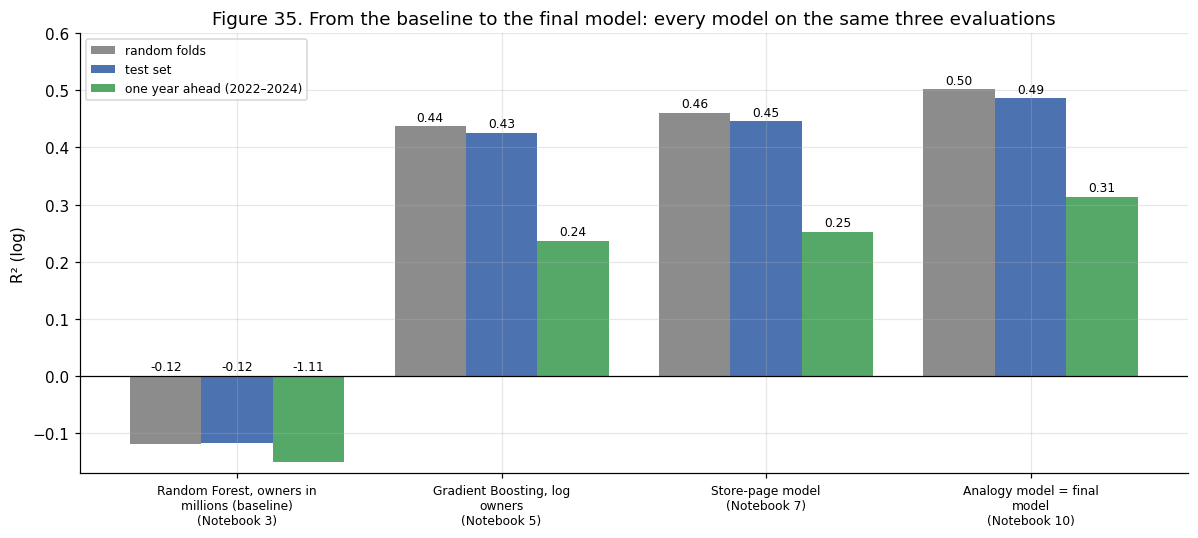

,From,Variables,Random folds: R² (log),One year ahead: R² (log),Test: R² (log),Test: R² (owners),Test: MAE (millions of owners)
Model,,,,,,,
"Parent paper 1 method: Linear Regression, owners in millions",Notebook 3,42,-24.191,-72.557,-24.271,0.035,0.203
"Parent paper 1 method: Decision Tree, owners in millions",Notebook 3,42,-0.197,-0.925,-0.209,-0.374,0.173
"Random Forest, owners in millions (baseline)",Notebook 3,42,-0.119,-1.110,-0.117,0.340,0.157
"Gradient Boosting, log owners",Notebook 5,42,0.437,0.237,0.425,0.075,0.110
Store-page model,Notebook 7,49,0.460,0.253,0.446,0.167,0.107
Analogy model = final model,Notebook 10,59,0.502,0.313,0.486,0.199,0.106


In [8]:
MODELS = [
    ("Parent paper 1 method: Linear Regression, owners in millions", "Notebook 3", LinearRegression(), BASE, "raw"),
    ("Parent paper 1 method: Decision Tree, owners in millions", "Notebook 3", DecisionTreeRegressor(random_state=RANDOM_STATE), BASE, "raw"),
    ("Random Forest, owners in millions (baseline)", "Notebook 3", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), BASE, "raw"),
    ("Gradient Boosting, log owners", "Notebook 5", gb(), BASE, "log"),
    ("Store-page model", "Notebook 7", gb(), STORE_PAGE, "log"),
    ("Analogy model" + ("" if ADOPT_TUNED else " = final model"), "Notebook 10", gb(), ANALOGY, "log"),
] + ([("Final model (tuned)", "Notebook 11", gb(FINAL_PARAMS), ANALOGY, "log")] if ADOPT_TUNED else [])


def fit_predict_log(model, features, target, fit_frame, score_frame):
    """Predictions on the log scale; raw-target models are converted with log1p(max(prediction, 0))."""
    if target == "raw":
        p = clone(model).fit(fit_frame[features], fit_frame["owners"] / 1e6).predict(score_frame[features]) * 1e6
        return np.log1p(np.clip(p, 0, None))
    return clone(model).fit(fit_frame[features], fit_frame["log_owners"]).predict(score_frame[features])


rows = []
for name, source, model, features, target in MODELS:
    oof = np.zeros(len(train))
    for tr, va in folds:
        oof[va] = fit_predict_log(model, features, target, train.iloc[tr], train.iloc[va])
    ahead_values = []
    for year in AHEAD_YEARS:
        earlier, scored = train[train["release_year"] < year], train[train["release_year"] == year]
        ahead_values.append(r2_score(scored["log_owners"], fit_predict_log(model, features, target, earlier, scored)))
    test_log = fit_predict_log(model, features, target, train, test)
    rows.append({"Model": name, "From": source, "Variables": len(features),
                 "Random folds: R² (log)": r2_score(train["log_owners"], oof),
                 "One year ahead: R² (log)": np.mean(ahead_values),
                 "Test: R² (log)": r2_score(test["log_owners"], test_log),
                 "Test: R² (owners)": r2_score(test["owners"] / 1e6, np.expm1(test_log) / 1e6),
                 "Test: MAE (millions of owners)": mean_absolute_error(test["owners"] / 1e6, np.expm1(test_log) / 1e6)})
    print(f"{name}: done")
table60 = pd.DataFrame(rows).set_index("Model")
table60.to_csv(os.path.join(TAB_DIR, "table60_final_comparison.csv"))

fig, ax = plt.subplots(figsize=(11, 5))
shown = table60.iloc[2:]                  # Linear Regression and Decision Tree fall far below zero on the log scale
x = np.arange(len(shown))
for offset, column, color, label in [(-0.27, "Random folds: R² (log)", GREY, "random folds"),
                                     (0, "Test: R² (log)", BLUE, "test set"),
                                     (0.27, "One year ahead: R² (log)", GREEN, "one year ahead (2022–2024)")]:
    values = shown[column].clip(lower=-0.15)
    ax.bar(x + offset, values, 0.27, color=color, label=label)
    for xi, v, raw in zip(x + offset, values, shown[column]):
        ax.text(xi, max(v, 0) + 0.01, f"{raw:.2f}", ha="center", fontsize=8)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels([textwrap.fill(n, 24) + f"\n({s})" for n, s in zip(shown.index, shown["From"])], fontsize=8)
ax.set_ylabel("R² (log)")
ax.set_ylim(-0.17, 0.6)
ax.legend(fontsize=8, loc="upper left")
ax.set_title("Figure 35. From the baseline to the final model: every model on the same three evaluations")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig35_final_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()
table60.style.format({"Variables": "{:,}", "Random folds: R² (log)": "{:.3f}", "One year ahead: R² (log)": "{:.3f}",
                      "Test: R² (log)": "{:.3f}", "Test: R² (owners)": "{:.3f}",
                      "Test: MAE (millions of owners)": "{:.3f}"}).set_caption(
    "Table 60. Every model of the study on the same evaluations (one year ahead: seed 42, mean of 2022–2024)")

**Interpretation.**
- **The first parent paper's methods fail once the leak is removed.** On the log scale Linear Regression scores
  −24.2 (39% of its predictions are negative owners), the Decision Tree −0.20 and the baseline Random Forest
  −0.12: all worse than predicting the average.
- **Each adopted change adds to the next.** Random-fold R² (log): 0.437 with the log target and Gradient
  Boosting, 0.460 with studio experience and lead time, 0.502 with the predecessor and studio averages.
  Test: 0.426 → 0.446 → 0.486. One year ahead: 0.237 → 0.253 → 0.313.
- **Mean absolute error on the test set falls by a third**, from 0.157 million owners for the baseline Random
  Forest to 0.106 million.
- **R² in owners rather than log owners stays low (0.199 for the final model).** It is dominated by a few dozen
  blockbusters (Notebook 5). The baseline Random Forest's 0.340 on that scale is an artefact of which
  blockbusters landed in the test set; its cross-validated value was 0.013.

---
## 16.5 Findings and decision

**Final model.** Gradient Boosting (default settings) on log1p(estimated owners) with 59 variables: 42
store-page variables from Notebook 1, studio experience and store-page lead time (Notebook 7), and the owners of
the game's predecessor and the studio's earlier games (Notebook 10).

| Evaluation | R² (log) |
|---|---|
| Random folds | 0.502 |
| Test set | 0.486 |
| One year ahead (2022–2024) | 0.311 |
| One year ahead, games with a series predecessor | 0.588 |
| One year ahead, games with no predecessor | 0.089 |

**What the study found.**
1. **The first parent paper's R² of 1.00 came from leaking variables.** With only pre-release information its
   methods explain nothing.
2. **The target's scale matters most.** Predicting log owners with Gradient Boosting turned a model worse than
   the average into one explaining 44% of the variance.
3. **Store-page information alone reaches about 0.25 one year ahead.** Studio experience and lead time help a
   little; tuning does not.
4. **A game's history is the strongest information available before release.** The predecessor and the studio's
   track record, the idea taken from the third paper, raise one-year-ahead R² from 0.25 to 0.31.
5. **How predictable a game is depends on whether it has a history.** Games in a series can be forecast
   reasonably (0.59 one year ahead); a studio's first game, and free-to-play games, cannot.
6. **All effects are associations, not causes.**

**Limitations.**
- Owners are SteamSpy estimates in ranges, 70% of games share the lowest range, and counts are a 2025 snapshot.
  The predecessor and studio variables are therefore read after the predicted game's release (Notebook 10,
  Section 15.5).
- Viral hits and free-to-play successes are not predictable from information available before release.
- No pre-release interest measure (wishlists, search volume) was available; Google Trends does not reach
  mid-range games (E20).

**Decision.** The analogy model with default settings is the final model. The modelling stage of the study is
complete.